# make the model alike to DCMEX conditions

In [2]:
import sys
import math
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset # !! new - building netcdf
import os # file saving 
import xarray as xr
from pathlib import Path
import importlib.util
from glob import glob
import seaborn as sns
import imageio 
import tempfile
import pandas as pd

## era5
* average over area for profile?
* over mountainous region only - zoom in even more onto the mountins - track of where the aircraft passed?

In [4]:
pth = '/gws/ssde/j25a/dcmex/users/ezriab/era5/'
name = '19th_july_2022.nc'
ncfile = xr.open_dataset(f"{pth}{name}", decode_times=True)


/home/users/esree/miniforge3/envs/vs_code_envi/lib/python3.13/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [5]:
ncfile

<xarray.Dataset> Size: 5MB
Dimensions:         (valid_time: 24, pressure_level: 32, latitude: 13,
                     longitude: 13)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 192B 2022-07-19 ... 2022-07-1...
  * pressure_level  (pressure_level) float64 256B 1e+03 975.0 950.0 ... 5.0 2.0
  * latitude        (latitude) float64 104B 35.0 34.75 34.5 ... 32.5 32.25 32.0
  * longitude       (longitude) float64 104B -108.0 -107.8 ... -105.2 -105.0
    number          int64 8B ...
    expver          (valid_time) <U4 384B ...
Data variables:
    r               (valid_time, pressure_level, latitude, longitude) float32 519kB ...
    ciwc            (valid_time, pressure_level, latitude, longitude) float32 519kB ...
    clwc            (valid_time, pressure_level, latitude, longitude) float32 519kB ...
    q               (valid_time, pressure_level, latitude, longitude) float32 519kB ...
    crwc            (valid_time, pressure_level, latitude, longitude) float32 519kB ...
    cswc            (valid_time, pressure_level, latitude, longitude) float32 519kB ...
    t               (valid_time, pressure_level, latitude, longitude) float32 519kB ...
    u               (valid_time, pressure_level, latitude, longitude) float32 519kB ...
    v               (valid_time, pressure_level, latitude, longitude) float32 519kB ...
    w               (valid_time, pressure_level, latitude, longitude) float32 519kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-19T10:48 GRIB to CDM+CF via cfgrib-0.9.1...

## dropsonde
* use this to make a profile of pressure? 

In [2]:
import sys
sys.path.append('/home/users/esree/dcmex_instruments/faam_data/')
# faam functions
from faam_data_functions import time_adjust, get_nc_variable, mask_data, flatten_20hz_variable, mo_mean, datetime_to_sec, cloud_pass_time, make_cdp_psd
from faam_data_functions_v2 import faam_mo_files_v2, make_cdp_psd_v2, make_cdp_conc

sys.path.append('/home/users/esree/dcmex_instruments/Manchester_ice/')
# manchester ice functions
from manchester_ice_function import manc_ice_files, manc_2ds_variable, manc_hvps_variable, tas_adjustment, unit_adjustment

sys.path.append('/home/users/esree/dcmex_instruments/cnn_labelled_ice/')
# functions for my cnn labelled ice
from cnn_ice_functions import cnn_ice_files, cnn_labelled_df, sum_habit_conc, unit_adjustment_ezri_ice

## stick to 30th rn
date = '220730'
# e.g.

faam_mo_paths_dic = faam_mo_files_v2() # dictionary containing dates + paths to nc files
date_dict = faam_mo_paths_dic[date]
dropsonde_loc = '/badc/faam/data/2022/c307-jul-30/core_processed/faam-dropsonde_faam_20220730160054_r0_c307_proc.nc'

ds_f = xr.open_mfdataset(dropsonde_loc)
ds_f

/home/users/esree/miniforge3/envs/vs_code_envi/lib/python3.13/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


<xarray.Dataset> Size: 140kB
Dimensions:         (time: 1670, obs: 1)
Coordinates:
  * time            (time) datetime64[ns] 13kB 2022-07-30T16:07:51.290008544 ...
    lat             (time) float32 7kB dask.array<chunksize=(1670,), meta=np.ndarray>
    lon             (time) float32 7kB dask.array<chunksize=(1670,), meta=np.ndarray>
    gpsalt          (time) float32 7kB dask.array<chunksize=(1670,), meta=np.ndarray>
Dimensions without coordinates: obs
Data variables: (12/27)
    trajectory      |S1 1B ...
    launch_time     datetime64[ns] 8B ...
    pres            (time) float32 7kB dask.array<chunksize=(1670,), meta=np.ndarray>
    tdry            (time) float32 7kB dask.array<chunksize=(1670,), meta=np.ndarray>
    dp              (time) float32 7kB dask.array<chunksize=(1670,), meta=np.ndarray>
    rh              (time) float32 7kB dask.array<chunksize=(1670,), meta=np.ndarray>
    ...              ...
    reference_rh    (obs) float32 4B dask.array<chunksize=(1,), meta=np.ndarray>
    reference_wspd  (obs) float32 4B dask.array<chunksize=(1,), meta=np.ndarray>
    reference_wdir  (obs) float32 4B dask.array<chunksize=(1,), meta=np.ndarray>
    reference_lat   (obs) float32 4B dask.array<chunksize=(1,), meta=np.ndarray>
    reference_lon   (obs) float32 4B dask.array<chunksize=(1,), meta=np.ndarray>
    reference_alt   (obs) float32 4B dask.array<chunksize=(1,), meta=np.ndarray>
Attributes: (12/93)
    Conventions:            CF-1.6
    RepoRevision:           V3.4.6
    RepoLastChangedDate:    Fri Apr 30 16:17:27 2021 -0600
    RepoId:                 163b1128fa837a96c93dfe8a59c915ff3185b748
    RepoBranch:             HEAD
    featureType:            trajectory
    ...                     ...
    WindQCDev:              999
    WindQCWL:               30
    WindSats:               6
    WindSmoothWL:           10
    WindVVPresWL:           5
    WindVVdelta:            2.5

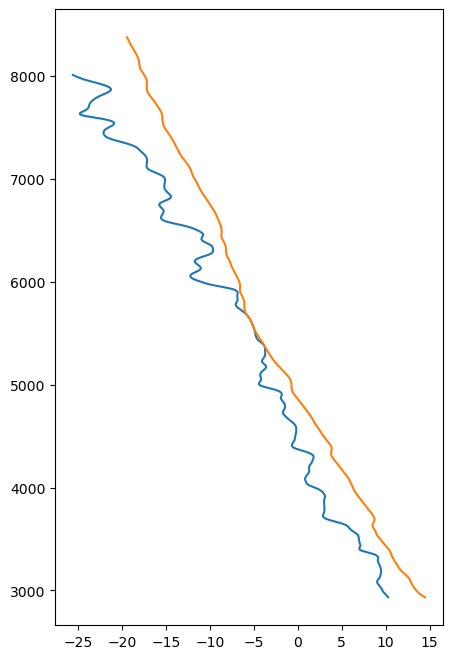

In [3]:
alt = ds_f["gpsalt"].compute()
#wdir = ds_f["wdir"].compute()
#mr = ds_f["mr"].compute()
tdry = ds_f["tdry"].compute()
dp = ds_f["dp"].compute()
mask = np.isfinite(dp) & np.isfinite(alt) # only plot where both have values - lot of nans
mask2 = np.isfinite(tdry) & np.isfinite(alt) # only plot where both have values - lot of nans
plt.figure(figsize=(5, 8))
plt.plot(dp[mask], alt[mask])
plt.plot(tdry[mask2], alt[mask2])


In [8]:
# need to convert this g/kg to g/m3 -> need air density

specif_gas_constant = 287.058 # J/kg/K

density = ds_f["pres"].compute()*100 / (specif_gas_constant * ds_f["tdry"].compute()) # kg/m3

lwc = mr * density / 1000 # g/m3

Text(0, 0.5, 'GPS Altitude (m)')

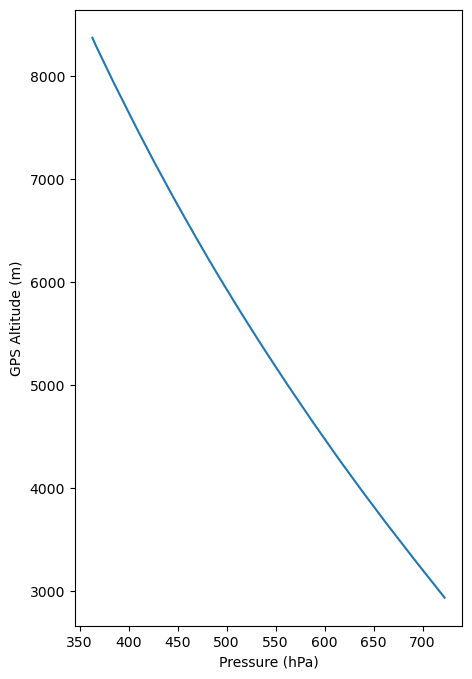

In [5]:
alt = ds_f["gpsalt"].compute()
wdir = ds_f["wdir"].compute()
pressure = ds_f["pres"].compute()
mask = np.isfinite(pressure) & np.isfinite(alt) # only plot where both have values - lot of nans

plt.figure(figsize=(5, 8))
plt.plot(pressure[mask], alt[mask])
plt.xlabel("Pressure (hPa)")
plt.ylabel("GPS Altitude (m)")


## radiosonde
* using sonde to calculate temp and pressure at cloud base?

In [3]:
sonde_loc = '/gws/ssde/j25a/dcmex/users/ezriab/sonde/'
_6pm_MT_30th = '2022073100-72365.csv'
_6am_MT_30th = '2022073012-72365.csv'

KAPPA = 0.2854          # R/cp for dry air (Poisson exponent)
EPS = 0.622             # ratio of gas constants, Rd/Rv

df = pd.read_csv(f"{sonde_loc}{_6am_MT_30th}")
df.columns = [c.strip() for c in df.columns]
sfc = df.iloc[0]                                   # lowest record = surface parcel
p0 = sfc["pressure_hPa"]                           # hPa
T0 = sfc["temperature_C"] + 273.15                 # K
Td0 = sfc["dew point temperature_C"] + 273.15      # K
w0 = sfc["mixing ratio_g/kg"]                      # g/kg
z0 = sfc["geopotential height_m"]                  # m

In [ ]:
# calculate lifting condensation level (LCL)?


In [5]:
am_30th

,time,longitude,latitude,pressure_hPa,geopotential height_m,temperature_C,dew point temperature_C,ice point temperature_C,relative humidity_%,humidity wrt ice_%,mixing ratio_g/kg,wind direction_degree,wind speed_m/s
0,2022-07-30 11:01:52,-106.6228,35.0380,842.8,1619,20.3,15.3,15.3,73,73,13.08,45,2.4
1,2022-07-30 11:01:53,-106.6228,35.0380,842.1,1626,20.3,15.2,15.2,73,73,13.03,16,1.1
2,2022-07-30 11:01:54,-106.6229,35.0380,841.5,1632,20.3,15.2,15.2,72,72,12.98,24,1.2
3,2022-07-30 11:01:55,-106.6229,35.0380,840.8,1639,20.3,15.1,15.1,72,72,12.93,31,1.3
4,2022-07-30 11:01:56,-106.6229,35.0380,840.1,1646,20.2,15.0,15.0,72,72,12.89,38,1.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6199,2022-07-30 12:45:11,-107.1189,35.0122,6.8,34153,-35.8,-65.6,-61.0,3,5,0.86,78,23.2
6200,2022-07-30 12:45:12,-107.1192,35.0122,6.8,34158,-35.9,-65.6,-61.1,3,5,0.86,77,23.2
6201,2022-07-30 12:45:13,-107.1195,35.0122,6.7,34164,-35.9,-65.6,-61.1,3,5,0.87,77,23.1
6202,2022-07-30 12:45:14,-107.1197,35.0121,6.7,34170,-35.9,-65.6,-61.1,3,5,0.86,77,23.1


# radar

In [1]:
????

Object `??` not found.


# aircraft